<a href="https://colab.research.google.com/github/Evertonh0/Computacao-e-solucao-de-Problemas/blob/main/m16_trabalho_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Parte 0:** Conectando no API

- API último sorteio de 2026: https://servicebus2.caixa.gov.br/portaldeloterias/api/megasena/3084




In [1]:
# Importando o módulo requests:
import requests as req

# Usando o API fornecida no moodle:
API = 'https://servicebus2.caixa.gov.br/portaldeloterias/api/megasena/'

# Solicitando dados do site:
resp = req.get('https://servicebus2.caixa.gov.br/portaldeloterias/api/megasena/')

# Vendo se vai dar bom (tem que dar 200 para conectar no API):
print(resp.status_code)
if resp.status_code == 200:
  print('Deu bom! Conseguiu conectar no API.')
else:
  print('Não deu bom! Não deu pra conectar no API.')


200
Deu bom! Conseguiu conectar no API.


### **Parte 1:**
- Ao longo do ano de 2026, qual é o ranking das 3 dezenas mais sorteadas na Mega-Sena?
- Quantas vezes cada uma destas dezenas foi sorteada e qual o percentual de ocorrência destas dezenas em relação a todas as dezenas sorteadas no ano de 2026?


In [27]:
# extração inicial dos dados:
if resp.status_code == 200:
  data = resp.json()

# Criando o ponto de partida do loop e guardando numa lista vazia:
sorteio_atual = 3084  #
sorteios_2026 = []

# MOntando o loop:
while True:
  link = f'https://servicebus2.caixa.gov.br/portaldeloterias/api/megasena/{sorteio_atual}'
  resp = req.get(link)

  if resp.status_code == 200:
    dados = resp.json()
    data_apuracao = dados['dataApuracao']

    # Guardando as dezenas caso forem de 2026:
    if '2026' in data_apuracao:
      sorteios_2026.extend(dados['listaDezenas'])
      sorteio_atual -= 1 # MUdando de sorteio de 1 a 1 até nao ser mais 2026.

    else:
      break  # parando o loop.

      time.sleep(1)  # Caso de pau no servidor.

print(f'O total de dezenas de 2026 foi {len(sorteios_2026)}')
# Foram 130 sorteios (contando até o 3084, não considerei o 3085 do dia 15/11) ao longo de 2026 vezes 6 dezenas de cada sorteio, logo 780 dezenas

# Contando as dezenas de 2026:
frequencia_das_dezenas = {}

for dezena in sorteios_2026:
  if dezena in frequencia_das_dezenas:

    frequencia_das_dezenas[dezena] += 1 # Se já tiver aparecido, soma 1.

  else:
    frequencia_das_dezenas[dezena] = 1 # Se não apareceu.

# Criando uma função pra guardar a contagem:
def pegar_qtd_dezenas(item):
  return item[1]

# Ordenando por ordem crescente a contagem:
frequencia_dezenas_ordenado = sorted(frequencia_das_dezenas.items(), key = pegar_qtd_dezenas, reverse = True)

top3_mais_sorteadas = frequencia_dezenas_ordenado[:3]

total_dezenas_mais_sorteadas = len(sorteios_2026)

# Calculando a porcetagem:
for posicao, (dezena, qtd) in enumerate(top3_mais_sorteadas, start = 1):

  porcentagem = (qtd/ total_dezenas_mais_sorteadas) * 100
  print(f'Em {posicao} lugar a dezena {dezena}. Qtd de vezes que saiu {qtd}. {porcentagem:.2f}%')


O total de dezenas de 2026 foi 780
Em 1 lugar a dezena 06. Qtd de vezes que saiu 22. 2.82%
Em 2 lugar a dezena 58. Qtd de vezes que saiu 20. 2.56%
Em 3 lugar a dezena 43. Qtd de vezes que saiu 19. 2.44%


### **Parte 2:**

- Ao longo do ano de 2026, qual é o ranking das 3 dezenas menos sorteadas na Mega-Sena? Para isto o programa desenvolvido deve gerar uma lista que obrigatoriamente seja nomeada como mis_rak_min_csp

- Quantas vezes cada uma destas dezenas foi sorteada e qual o percentual de ocorrência destas dezenas em relação a todas as dezenas sorteadas em 2026?

In [3]:
# Reaproveitei a linha 47 da parte 1:
top3_menos_sorteadas = sorted(frequencia_das_dezenas.items(), key = pegar_qtd_dezenas, reverse = False)

# GUardando na lista obrigatória:
mis_rak_min_csp = top3_menos_sorteadas[:3]

total_dezenas_menos_sorteadas = len(sorteios_2026)

# Ordenando por ordem descrescente a contagem e calculando a porcentagem:
for posicao, (dezena, qtd) in enumerate(mis_rak_min_csp, start = 1):

    porcentagem = (qtd/ total_dezenas_menos_sorteadas) * 100

    print(f' Em {posicao} lugar a dezena {dezena}. Qtd de vezes que saiu {qtd}. {porcentagem:.2f} %)')



 Em 1 lugar a dezena 34. Qtd de vezes que saiu 4. 0.51 %)
 Em 2 lugar a dezena 12. Qtd de vezes que saiu 6. 0.77 %)
 Em 3 lugar a dezena 26. Qtd de vezes que saiu 7. 0.90 %)


### **Parte 3**:

- Em qual concurso da Mega-Sena houve o menor número de vencedores na faixa de premiação de 5 acertos em 2026?
 Para isto o programa desenvolvido deve gerar uma variável que obrigatoriamente seja nomeada como misa_cin_five_csp

- Para sua implementação você deve desconsiderar os concursos em que não houveram vencedores, e caso houver mais de um concurso com o mesmo número mínimo de vencedores, todos estes concursos deverão ser apresentados ao usuário.


In [4]:
import requests as req
import time

# Definindo meu ponto de partida e guardando a contagem:
sorteio_atual = 3084
concursos_2026 = []
tentativas = 0

# Conectando no API:
while True:
    link = f'https://servicebus2.caixa.gov.br/portaldeloterias/api/megasena/{sorteio_atual}'
    resp = req.get(link, timeout = 15)

    # PUxando os dadoos:
    if resp.status_code == 200:
        tentativas = 0
        dados = resp.json()
        data_apuracao = dados.get('dataApuracao', '')

        if '2026' in data_apuracao:
            concursos_2026.append(dados)
            sorteio_atual -= 1 # número, dataAPuracao e listaRateioPremio do API.

        else:
            break # chegou em 2025, então para

    else:
        tentativas += 1
        if tentativas >= 5:

            break
        time.sleep(1) # Caso de ruim no servidor.

# Printando os 130 sorteios de 2026. De novo, não considerei o sorteio 3085 do dia 15/11.
print(f'em 2026 tiveram {len(concursos_2026)} sorteios')


# Lista com 1 ganhador:
um_ganhador = []

for concurso in concursos_2026:
    numero_concurso = concurso.get('numero')
    data_concurso = concurso.get('dataApuracao')

    # PEgando a lista de faixas de premiação:
    rateio = concurso.get('listaRateioPremio', [])

    for faixa in rateio:
        # Filtrando só a faixa de 5 acertos (faixa 2)
        if faixa.get('faixa') == 2:
            ganhadores = faixa.get('numeroDeGanhadores', 0)

            # Desconsiderarando os concursos sem nenhum vencedor:
            if ganhadores > 0:
                um_ganhador.append({
                    'concurso': numero_concurso,
                    'ganhadores': ganhadores,
                    'data': data_concurso
                })

# Guardando dados:
if um_ganhador:
    menor_ganhadores = min(item['ganhadores'] for item in um_ganhador)

    # os empates:
    misa_cin_five_csp = [item for item in um_ganhador if item['ganhadores'] == menor_ganhadores]

    print(f'quantidade de ganhadores na faixa de premiação de 5 acertos: {menor_ganhadores} ganhadores')

    # Botando em ordem:
    for posicao, c in enumerate(misa_cin_five_csp, start=1):
        print(f'concurso {c['concurso']}, data: {c['data']}, ganhadores: {c['ganhadores']}')
else:
    print('sei lá!')  # POde demorar um pouco, mas vai executar certinho.



em 2026 tiveram 130 sorteios
quantidade de ganhadores na faixa de premiação de 5 acertos: 7 ganhadores
concurso 3023, data: 25/06/2026, ganhadores: 7


### **Parte 4**
- Em quantos concursos não houve ganhadores da Mega-Sena na faixa de 6 acertos (**faixa 1**)?


In [5]:
# sorteios sem ganhador na sena faixa 1:       (Reaproveitando a lista concursor_2026.)
sem_ganhador_sena = []

for concurso in concursos_2026:
    numero_concurso = concurso.get('numero')
    data_concurso = concurso.get('dataApuracao')

    # Pegando a lista de faixas de premiação:
    rateio = concurso.get('listaRateioPremio', [])

    for faixa in rateio:

        # Filtrando só a faixa de 6 acerto  (faixa 1)
        if faixa.get('faixa') == 1:
            ganhadores = faixa.get('numeroDeGanhadores', 0)

            # Pegando só os concursos sem nenhum vencedor:
            if ganhadores == 0:
                sem_ganhador_sena.append({
                    'concurso': numero_concurso,
                    'data': data_concurso
                })

#Printando o resultado:
if sem_ganhador_sena:

    print(f'Concursos sem ganhador na sena no ano de 2026: {len(sem_ganhador_sena)}')

#colocar em ordem:
    for posicao, c in enumerate(sem_ganhador_sena, start = 1):

        print(f'{posicao}. Concurso: {c['concurso']}, Data: {c['data']}')

else:
    print('Todos os concursos de 2026 tiveram ganhador na sena.')


Concursos sem ganhador na sena no ano de 2026: 112
1. Concurso: 3082, Data: 06/11/2026
2. Concurso: 3081, Data: 04/11/2026
3. Concurso: 3080, Data: 01/11/2026
4. Concurso: 3079, Data: 30/10/2026
5. Concurso: 3078, Data: 29/10/2026
6. Concurso: 3076, Data: 27/10/2026
7. Concurso: 3075, Data: 26/10/2026
8. Concurso: 3074, Data: 24/10/2026
9. Concurso: 3073, Data: 22/10/2026
10. Concurso: 3072, Data: 20/10/2026
11. Concurso: 3071, Data: 18/10/2026
12. Concurso: 3070, Data: 14/10/2026
13. Concurso: 3069, Data: 11/10/2026
14. Concurso: 3068, Data: 08/10/2026
15. Concurso: 3067, Data: 06/10/2026
16. Concurso: 3066, Data: 03/10/2026
17. Concurso: 3065, Data: 01/10/2026
18. Concurso: 3064, Data: 29/09/2026
19. Concurso: 3063, Data: 27/09/2026
20. Concurso: 3062, Data: 24/09/2026
21. Concurso: 3061, Data: 22/09/2026
22. Concurso: 3060, Data: 20/09/2026
23. Concurso: 3058, Data: 15/09/2026
24. Concurso: 3057, Data: 13/09/2026
25. Concurso: 3056, Data: 10/09/2026
26. Concurso: 3055, Data: 08/09/2

### **Parte 5**
- Qual foi o concurso da Mega-Sena, em 2026, que pagou o maior prêmio para a quina (5 acertos)?
- Qual foi a data deste concurso?

In [23]:
# Guardando maior prêmio da quina:
maior_valor = 0
concursos_maior = []

for concurso in concursos_2026:
    numero_concurso = concurso.get('numero')
    data_concurso = concurso.get('dataApuracao')

    # Pegando lista de faixas de premiação:
    rateio = concurso.get('listaRateioPremio', [])

    for faixa in rateio:

        # Filtrando a faixa de 5 acertos
        if faixa.get('faixa') == 2:
            ganhadores = faixa.get('numeroDeGanhadores', 0)
            valor = faixa.get('valorPremio', 0)

            # TIrando os concursos com nenhum vencedor:
            if ganhadores > 0:

                # Se o valor for maior que o maior até agora troca:
                if valor > maior_valor:
                    maior_valor = valor
                    concursos_maior = [{
                        'concurso': numero_concurso,
                        'data': data_concurso,
                        'ganhadores': ganhadores
                    }]

                # Se for igual é empate e guarda também:
                elif valor == maior_valor:
                    concursos_maior.append({
                        'concurso': numero_concurso,
                        'data': data_concurso,
                        'ganhadores': ganhadores
                    })

# printando o resultado:
if len(concursos_maior) > 0:

    # pintando o resultado:
  if len(concursos_maior) > 0:

    print(f'O maior prêmio da quina em 2026 foi de r$ {round(maior_valor, 2)}')

    #Colocando em ordem:
    for posicao, c in enumerate(concursos_maior, start=1):
        print(f'Concurso: {c['concurso']}. Data: {c['data']}. Ganhadores: {c['ganhadores']}')
else:
    print('nenhum concurso com ganhador na quina.')



O maior prêmio da quina em 2026 foi de r$ 117144.19
Concurso: 3023. Data: 25/06/2026. Ganhadores: 7


### **Parte 6**

- Qual foi o valor médio pago aos vencedores da quadra (faixa de 4 acertos) durante o ano de 2026?

In [14]:
soma = 0
qtd_concursos = 0
total_pago = 0
total_ganhadores = 0

for concurso in concursos_2026:

    # Pegando lista das faixas da premiação:
    rateio = concurso.get('listaRateioPremio', [])

    for faixa in rateio:
        # Só a faixa 3
        if faixa.get('faixa') == 3:
            ganhadores = faixa.get('numeroDeGanhadores', 0)
            valor = faixa.get('valorPremio', 0)

            # Sem ganhador não conta:
            if ganhadores > 0:
                soma += valor
                qtd_concursos += 1

                total_pago += valor * ganhadores
                total_ganhadores += ganhadores

# Calculando as media:
media_concursos = soma / qtd_concursos
media_ganhador = total_pago / total_ganhadores

print(f'Concursos com ganhador na quadra: {qtd_concursos}')
print(f'Total de ganhadores: {total_ganhadores}')
print(f'media dos concursos: R {round(media_concursos, 2)}')
print(f'media por ganhador: R$ {round(media_ganhador, 2)}')

Concursos com ganhador na quadra: 130
Total de ganhadores: 911385
media dos concursos: R 934.66
media por ganhador: R$ 628.96


### **Parte 7:**

- Buscar e apresentar qual foi o concurso que obteve o maior número de ganhadores em todas as faixas de sorteio, isto é, deve-se somar os ganhadores com 6, 5 e 4 acertos.
- O número do concurso com maior número de vencedores deve ser apresentado, bem como sua data de realização.

In [11]:
maior = 0
concurso_maior = 0
data_maior = ''

for concurso in concursos_2026:
    total = 0

    rateio = concurso.get('listaRateioPremio', [])

    for faixa in rateio:
        if faixa.get('faixa') == 1:
            total += faixa.get('numeroDeGanhadores', 0)
        if faixa.get('faixa') == 2:
            total += faixa.get('numeroDeGanhadores', 0)
        if faixa.get('faixa') == 3:
            total += faixa.get('numeroDeGanhadores', 0)

    # Se o total for maior que o maior, troca:
    if total > maior:
        maior = total
        concurso_maior = concurso.get('numero')
        data_maior = concurso.get('dataApuracao')

print(f'concurso: {concurso_maior}')
print(f'data: {data_maior}')
print(f'total ganhadores: {maior}')

concurso: 2955
data: 01/01/2026
total ganhadores: 312242


### **Parte 8:**
 - O seu programa deverá apresentar um gráfico com a evolução dos valores arrecadados em 2026, isto é, deve-se computar os valores do primeiro concurso até o último concurso realizado.

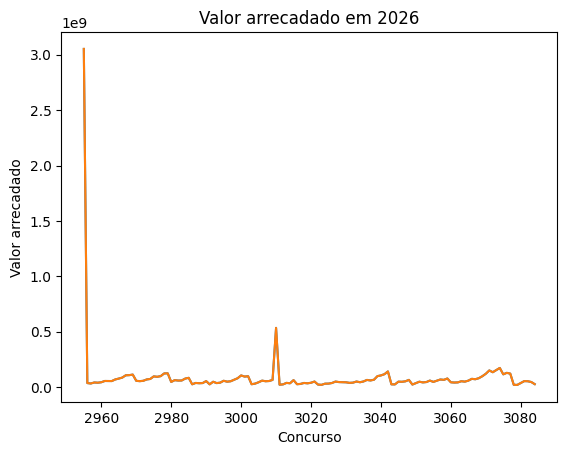

In [24]:
# IMportando a biblioteca de grafico:
import matplotlib.pyplot as plt

# Listas pro grafico:
numeros = []
valores = []

for concurso in concursos_2026:
    numeros.append(concurso.get('numero'))
    valores.append(concurso.get('valorArrecadado'))

# Invertend pra ficar do primeiro ate o ultimo:
numeros.reverse()
valores.reverse()

plt.plot(numeros, valores)
plt.title('Valor arrecadado em 2026')
plt.xlabel('Concurso')
plt.ylabel('Valor arrecadado')

#SAlvando o grafico:
plt.plot(numeros, valores)
plt.title('Valor arrecadado em 2026')
plt.xlabel('Concurso')
plt.ylabel('Valor arrecadado')
plt.savefig('grafico_arrecadacao_2026.png')
plt.show()

#printando:
plt.show()

### **Parte 9:**
- Por fim, o programa deve apresentar a impressão na tela da média de valores arrecadados pelos concursos em 2026.

In [13]:
# Media dos valores arrecadados:
soma = 0
qtd = 0

for concurso in concursos_2026:
    soma += concurso.get('valorArrecadado')
    qtd += 1

media = soma / qtd
print(f'Media arrecadada em 2026: R$ {round(media, 2)}')

Media arrecadada em 2026: R$ 87963234.83
